# Final report — the models on the screen data, with the thesis's yardsticks

The Larsch-lab screen is a second, much larger data set: one fish per 70 mm dish, a single dot always on screen,
five-minute episodes alternating bout-like and continuous motion (60–130 min used). The models were never trained on
it. Here M6 and F are simulated **unchanged** in the screen's experiment and judged with the same three yardsticks as on
our own recordings, on the **bout-like episodes only** (the motion our own dots have).

1. [Design](#design)
2. [Matched window classifier](#auc)
3. [Individuality](#indiv)
4. [Kinematics](#kin)
5. [Response to the dot by distance](#curves), [distance to the dot over the episode](#profiles)
6. [What it shows](#reading)
7. [Video: real fish against F](#video)
8. [Trained on the screen: M6 and D4 from scratch](#trained)
9. [Quick check: the dot's direction of motion as an input](#dmove)
10. [Matched window classifier](#matched)

<a id="design"></a>
## 1. Design

**Simulation** (`scripts/screen_eval.py`, reusing `twin_test.py`): M6 (seed 0 | 101 = keys 26e | 30d) and F (14f | 32b),
200 simulated fish per model and seed, each with a fresh latent, fold model *i* mod 5, the dot path of a median dish,
dish radius 35 mm (the wall inputs are relative to the radius), block clock held late (*t* = 60 s: the dot never
appears, it is always there), so **F's correction is off** and F runs as D4. Each model also runs **blind** (the same
fish, dot hidden): the reference that says what the dot response is worth.

**Real fish**: the 2 819 sighted reference siblings, positions → mm → bouts with the segmentation used for our data;
turn, displacement and interval measured onset to onset on both sides; intervals > 10 s dropped (0.34 % of bouts).

**Windows**: 60 consecutive bouts inside one bout-like episode, never across a dropped bout; per window the thesis's 39
features (`generative_metrics.window_features_traj`: turns 20, displacement 5, interval 5, fish-to-dot distance 5, radial
position 4).

**Matched classifier**: per replicate, a fresh **random sample of 200 real fish** (no selection by age) against the 200
simulated fish; the larger side subsampled to the same number of windows; random forest of 200 trees, 5-fold
cross-validation grouped by fish; 8 replicates (mean ± SD). Readings: all 39 features, without the 4 radial features,
and the 5 fish-to-dot features alone. **Floor**: real against real, two random 200-fish samples drawn from the two
halves of the clutches (no clutch on both sides).

**Individuality**: per fish, the mean of each of its windows; between-fish spread = SD of the per-fish means,
within-fish spread = mean of the per-fish SDs; simulated over real (target 1), all real fish, 95 % bootstrap over fish.

**Response by distance** (the screen's equivalent of the dot profiles, which need a block onset the screen does not
have): turn toward the dot, distance gained per bout and bouts per distance bin, each against the dot rotated about the
dish centre (no coupling to the fish); 95 % bootstrap over fish. M6, D4 and F.

In [ ]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
E = json.load(open("twin_test/screen_eval.json"))
ORDER = ["real vs real"] + [f"{m} s{s} {v}" for m in ("M6", "F") for s in (0, 101) for v in ("sighted", "blind")]
print(f"real: {E['n_real_fish']} fish, {E['n_real_windows']} windows of 60 bouts in bout-like episodes; "
      f"classifier: {E['reps']} replicates, {E['n_real_sample']} random real fish each")

real: 2809 fish, 54790 windows of 60 bouts in bout-like episodes; classifier: 8 replicates, 200 random real fish each


<a id="auc"></a>
## 2. Matched window classifier

$\mathrm{AUC}$ of a classifier telling real from simulated 60-bout windows (0.5 = indistinguishable). The floor is real
against real. **Sighted − blind**: how much the dot response changes the distinguishability (negative = the dot response
brings the simulated fish closer to real ones).

In [ ]:
def f(v): return f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}"
tab = pd.DataFrame({r: {k: f(E["auc"][r][k]) for k in ORDER} for r in E["auc"]})
print(tab.to_string())
print()
rows = {}
for m in ("M6", "F"):
    for s in (0, 101):
        rows[f"{m} s{s}"] = {r: f"{np.mean(E['auc'][r][f'{m} s{s} sighted']) - np.mean(E['auc'][r][f'{m} s{s} blind']):+.3f}"
                             for r in E["auc"]}
print("sighted - blind (mean over replicates):")
print(pd.DataFrame(rows).T.to_string())

                           all      no radial       dot only
real vs real     0.516 ± 0.023  0.515 ± 0.022  0.500 ± 0.003
M6 s0 sighted    0.946 ± 0.003  0.929 ± 0.004  0.698 ± 0.009
M6 s0 blind      0.963 ± 0.002  0.945 ± 0.004  0.813 ± 0.009
M6 s101 sighted  0.949 ± 0.002  0.930 ± 0.003  0.726 ± 0.007
M6 s101 blind    0.963 ± 0.002  0.947 ± 0.004  0.826 ± 0.009
F s0 sighted     0.950 ± 0.003  0.936 ± 0.004  0.712 ± 0.009
F s0 blind       0.962 ± 0.002  0.947 ± 0.003  0.815 ± 0.008
F s101 sighted   0.949 ± 0.003  0.935 ± 0.004  0.732 ± 0.009
F s101 blind     0.958 ± 0.002  0.943 ± 0.003  0.830 ± 0.008

sighted - blind (mean over replicates):
            all no radial dot only
M6 s0    -0.017    -0.016   -0.115
M6 s101  -0.014    -0.016   -0.100
F s0     -0.012    -0.011   -0.103
F s101   -0.009    -0.008   -0.098


### 2b. A scale: our own real fish against the screen fish

The screen fish come from another experiment and population (another rig, a wider and mostly older age range). To read
the model's $\mathrm{AUC}$, the same classifier compares **our own 15 real fish** with the screen fish, on the 30 features
that carry over between the two experiments (turns, displacement, interval; the dot and dish features do not). The
models are shown on the same 30 features. If our real fish are themselves easy to tell from the screen fish, the
model's level mostly reflects that population gap, which it inherited from the fish it was trained on.

In [ ]:
import os
if os.path.exists("twin_test/screen_eval_ref.json"):
    Rf = json.load(open("twin_test/screen_eval_ref.json"))
    order = ["real vs real", "our real fish"] + [k for k in ORDER[1:] if k in Rf["auc"]]
    print("turns + displacement + interval (30 features), against the screen's real fish:")
    print(pd.Series({k: f"{np.mean(Rf['auc'][k]):.3f} ± {np.std(Rf['auc'][k], ddof=1):.3f}" for k in order}).to_string())
    print()
    print(f"per-window medians (our {Rf['n_our_windows']} windows): |turn| mean {Rf['kin']['our'][0]:.1f} deg, "
          f"displacement SD {Rf['kin']['our'][1] / 3.6:.2f} mm, interval mean {Rf['kin']['our'][2]:.2f} s, "
          f"interval SD {Rf['kin']['our'][3]:.2f} s")
else:
    print("XX — scripts/screen_eval.py ref not run yet")

turns + displacement + interval (30 features), against the screen's real fish:
real vs real       0.510 ± 0.026
our real fish      0.870 ± 0.011
M6 s0 sighted      0.919 ± 0.004
M6 s0 blind        0.915 ± 0.004
M6 s101 sighted    0.916 ± 0.003
M6 s101 blind      0.914 ± 0.005
F s0 sighted       0.924 ± 0.004
F s0 blind         0.912 ± 0.003
F s101 sighted     0.926 ± 0.004
F s101 blind       0.909 ± 0.004

per-window medians (our 701 windows): |turn| mean 43.9 deg, displacement SD 4.42 mm, interval mean 1.38 s, interval SD 0.71 s


<a id="indiv"></a>
## 3. Individuality

Spread of the per-window means, simulated over real (target 1; 95 % bootstrap over fish). Real spreads in the last
rows (turn in degrees, displacement in mm, interval in s, radial position as r/R).

In [ ]:
ch = ["turn", "displacement", "interval", "radial"]
rows = []
for k, d in E["indiv"].items():
    for part in ("between", "within"):
        rows.append(dict(model=k, spread=part, **{c: f"{d['est'][part][j]:.2f} [{d['ci'][part][0][j]:.2f}, {d['ci'][part][1][j]:.2f}]"
                                                 for j, c in enumerate(ch)}))
print(pd.DataFrame(rows).set_index(["model", "spread"]).to_string())
r = next(iter(E["indiv"].values()))["real"]
print()
print(f"real ({r['n_fish']} fish): between " + ", ".join(f"{c} {v:.3g}" for c, v in zip(ch, r["between"]))
      + " | within " + ", ".join(f"{c} {v:.3g}" for c, v in zip(ch, r["within"])))

                              turn       displacement           interval             radial
model   spread                                                                             
M6 s0   between  0.99 [0.87, 1.08]  0.93 [0.81, 1.02]  2.31 [1.99, 2.58]  0.44 [0.40, 0.48]
        within   1.11 [1.07, 1.15]  1.18 [1.12, 1.25]  0.97 [0.93, 1.02]  0.78 [0.76, 0.81]
M6 s101 between  1.06 [0.94, 1.20]  1.03 [0.89, 1.16]  2.34 [1.98, 2.68]  0.46 [0.40, 0.51]
        within   1.24 [1.20, 1.29]  1.32 [1.26, 1.40]  0.96 [0.92, 1.00]  0.76 [0.74, 0.79]
F s0    between  1.25 [1.00, 1.52]  1.44 [1.13, 1.78]  2.30 [1.95, 2.70]  0.66 [0.57, 0.75]
        within   1.36 [1.31, 1.42]  1.65 [1.56, 1.75]  1.23 [1.17, 1.30]  0.76 [0.73, 0.79]
F s101  between  1.06 [0.94, 1.17]  0.97 [0.80, 1.15]  1.86 [1.64, 2.07]  0.43 [0.39, 0.47]
        within   1.32 [1.28, 1.37]  1.95 [1.86, 2.06]  1.45 [1.39, 1.51]  0.79 [0.76, 0.81]

real (2804 fish): between turn 6.1, displacement 1.01, interval 0.17, radial 0.

<a id="kin"></a>
## 4. Kinematics

Median over fish of each fish's mean over its windows (bout-like episodes): what the classifier has to work with.

In [ ]:
ch = ["|turn| (deg)", "displacement (mm)", "interval (s)", "radial (r/R)"]
print(pd.DataFrame({k: dict(zip(ch, [round(x, 3) for x in v])) for k, v in E["kin"].items()}).T.to_string())

                 |turn| (deg)  displacement (mm)  interval (s)  radial (r/R)
real                   37.661              4.215         1.165         0.473
M6 s0 sighted          41.837              4.288         1.382         0.459
M6 s0 blind            42.431              4.221         1.392         0.503
M6 s101 sighted        45.218              4.697         1.391         0.469
M6 s101 blind          45.100              4.526         1.347         0.511
F s0 sighted           44.597              4.647         1.351         0.464
F s0 blind             45.593              4.485         1.289         0.504
F s101 sighted         44.425              4.737         1.445         0.462
F s101 blind           44.766              4.562         1.413         0.511


<a id="curves"></a>
## 5. Response to the dot by distance

Real dot minus rotated dot, bout-like episodes. Real fish (black, 95 % band over fish) against M6, D4 and F (seed 0
filled and solid, seed 101 open and dashed; 95 % bootstrap over simulated fish). Occupancy is bouts per distance bin
over the rotated dot (1 = chance).

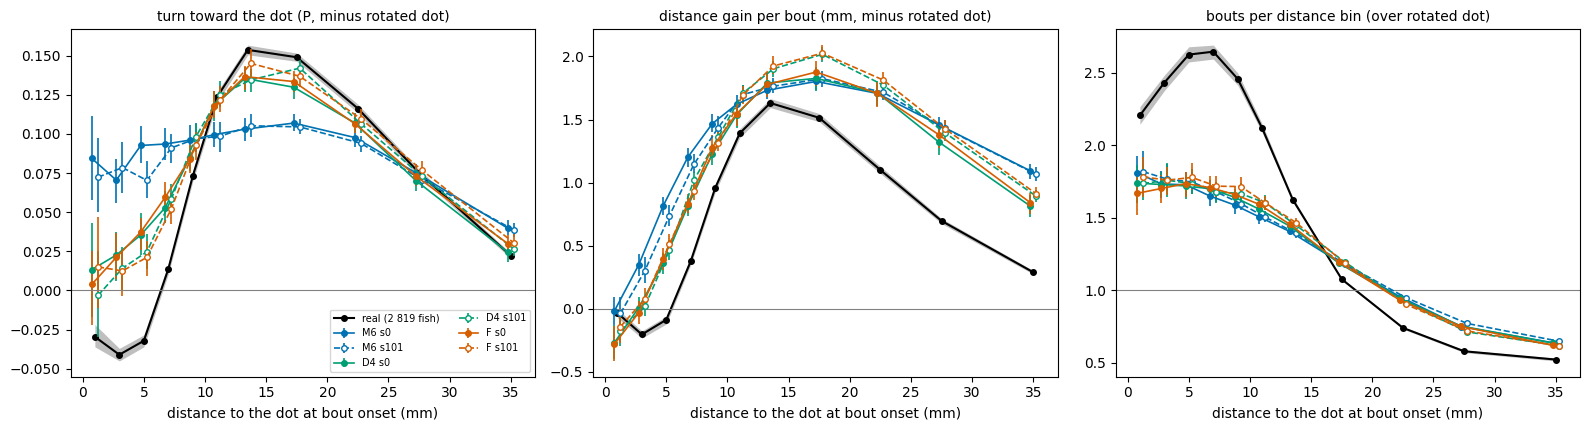

In [ ]:
b = np.array(E["dbins"]); xc = (b[:-1] + b[1:]) / 2; nb = 11
titles = ["turn toward the dot (P, minus rotated dot)", "distance gain per bout (mm, minus rotated dot)",
          "bouts per distance bin (over rotated dot)"]
col = {"M6": "#0072B2", "D4": "#009E73", "F": "#D55E00"}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
for j, ax in enumerate(axs):
    r = E["curves"]["real"]
    ax.fill_between(xc[:nb], np.array(r["lo"])[j, :nb], np.array(r["hi"])[j, :nb], color="0.75", lw=0)
    ax.plot(xc[:nb], np.array(r["est"])[j, :nb], "k-o", ms=4, label="real (2 819 fish)")
    for m in ("M6", "D4", "F"):
        for s, ls, mf in ((0, "-", col[m]), (101, "--", "white")):
            c = E["curves"][f"{m} s{s}"]
            y = np.array(c["est"])[j, :nb]
            err = np.vstack([y - np.array(c["lo"])[j, :nb], np.array(c["hi"])[j, :nb] - y])
            ax.errorbar(xc[:nb] + (0.25 if s else -0.25), y, yerr=err, fmt="o", ls=ls, color=col[m], mfc=mf,
                        ms=4, lw=1.2, capsize=0, label=f"{m} s{s}")
    ax.axhline(1.0 if j == 2 else 0.0, color="0.5", lw=0.8)
    ax.set_xlabel("distance to the dot at bout onset (mm)"); ax.set_title(titles[j], fontsize=10)
axs[0].legend(fontsize=7, ncol=2)
plt.tight_layout()

<a id="profiles"></a>
## 5b. Distance to the dot over the bout-like episode

The screen's dot never appears (it is always on screen), so there is no block onset to time a profile from. The nearest
equivalent is the **switch of the dot's motion from continuous to bout-like**, every ten minutes: time 0 is the start of
a bout-like episode, the 60 s before it are the end of the preceding continuous episode. Mean distance from the fish to
the dot at each bout onset, in 10 s bins, per fish and then over fish (95 % bootstrap over fish). Real fish follow a
continuous dot about half as strongly as a bout-like one (shoaling index 0.12 against 0.24), so they should close in
after the switch; the models see both kinds only as "moving". The dot's fixed path swings toward and away from the wall
about every 50 s, which every curve follows (top row); the bottom row removes it: each fish's distance to the rotated
dot minus its distance to the dot, i.e. how much closer than chance it stays. Grey dashed: real fish against the rotated
dot; dotted: the same model blind.

closer than chance (mm): last 60 s of continuous motion -> 60-300 s of bout-like motion
  real                2.76 ->  5.78  (change +3.02)
  M6 s0 sighted       3.15 ->  3.37  (change +0.23)
  M6 s101 sighted     3.15 ->  3.40  (change +0.25)
  F s0 sighted        3.72 ->  3.54  (change -0.18)
  F s101 sighted      3.54 ->  3.58  (change +0.04)
  M6 s0 blind         0.07 -> -0.08  (change -0.15)
  F s0 blind          0.01 ->  0.10  (change +0.09)


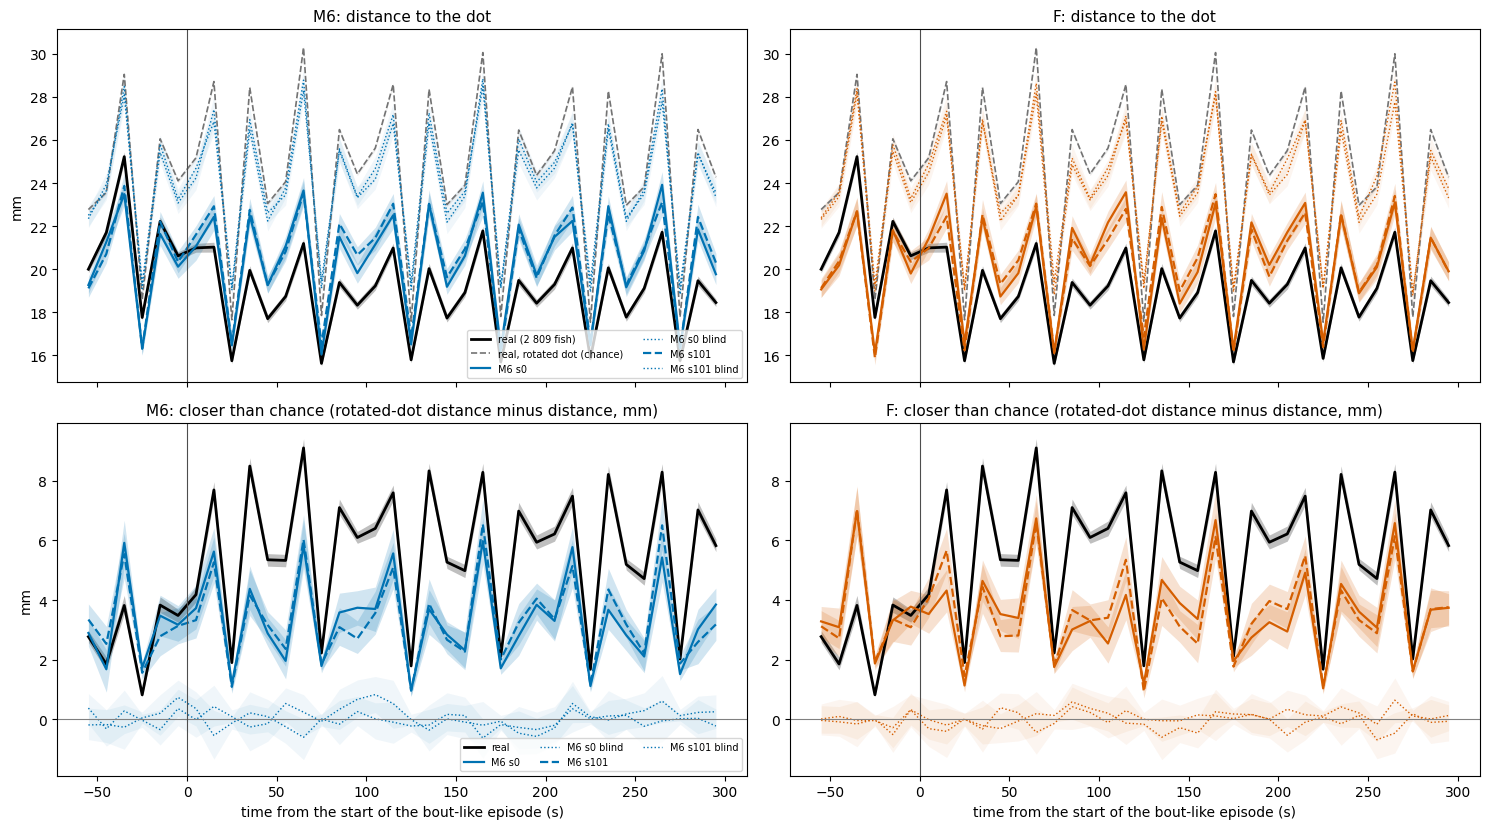

In [ ]:
P = json.load(open("twin_test/screen_profiles.json"))
b = np.array(P["bins"]); xc = (b[:-1] + b[1:]) / 2
col = {"M6": "#0072B2", "F": "#D55E00"}
fig, axs = plt.subplots(2, 2, figsize=(15, 8.4), sharex=True)
def band(ax, d, color, ls="-", lw=1.6, alpha=0.18, label=None):
    y = np.array(d["est"], float); lo = np.array(d["lo"], float); hi = np.array(d["hi"], float)
    ax.fill_between(xc, lo, hi, color=color, alpha=alpha, lw=0)
    ax.plot(xc, y, ls, color=color, lw=lw, label=label)
for c, m in enumerate(("M6", "F")):
    ax = axs[0, c]
    band(ax, P["prof"]["real"], "k", lw=2.0, alpha=0.25, label="real (2 809 fish)")
    band(ax, P["prof"]["real, rotated dot"], "0.45", ls="--", lw=1.2, alpha=0.12, label="real, rotated dot (chance)")
    for s, ls in ((0, "-"), (101, "--")):
        band(ax, P["prof"][f"{m} s{s} sighted"], col[m], ls=ls, label=f"{m} s{s}")
        band(ax, P["prof"][f"{m} s{s} blind"], col[m], ls=":", lw=1.0, alpha=0.06, label=f"{m} s{s} blind")
    ax.set_title(f"{m}: distance to the dot", fontsize=11)
    ax = axs[1, c]
    band(ax, P["attr"]["real"], "k", lw=2.0, alpha=0.25, label="real")
    for s, ls in ((0, "-"), (101, "--")):
        band(ax, P["attr"][f"{m} s{s} sighted"], col[m], ls=ls, label=f"{m} s{s}")
        band(ax, P["attr"][f"{m} s{s} blind"], col[m], ls=":", lw=1.0, alpha=0.06, label=f"{m} s{s} blind")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"{m}: closer than chance (rotated-dot distance minus distance, mm)", fontsize=11)
    ax.set_xlabel("time from the start of the bout-like episode (s)")
for ax in axs.ravel():
    ax.axvline(0, color="0.3", lw=0.8)
axs[0, 0].set_ylabel("mm"); axs[1, 0].set_ylabel("mm")
axs[0, 0].legend(fontsize=7, ncol=2, loc="lower right"); axs[1, 0].legend(fontsize=7, ncol=3, loc="lower right")
plt.tight_layout()
pre = (xc < 0); post = (xc > 60)
print("closer than chance (mm): last 60 s of continuous motion -> 60-300 s of bout-like motion")
for k in ("real", "M6 s0 sighted", "M6 s101 sighted", "F s0 sighted", "F s101 sighted",
          "M6 s0 blind", "F s0 blind"):
    y = np.array(P["attr"][k]["est"], float)
    print(f"  {k:18s} {np.nanmean(y[pre]):5.2f} -> {np.nanmean(y[post]):5.2f}  (change {np.nanmean(y[post]) - np.nanmean(y[pre]):+.2f})")

<a id="reading"></a>
## 6. What it shows

**The absolute classifier level is mostly the population, not the model.** The models are easy to tell from the screen
fish ($\mathrm{AUC}$ 0.946–0.950 with all features, 0.929–0.936 without the radial ones; floor 0.52). But on the 30
features that carry over between experiments, **our own real fish** are almost as easy to tell from them (0.870) as the
models are (0.91–0.93): the screen fish swim more regularly (median within-window SD of the interval 0.49 s against
0.71 s for our fish) and turn less, and the models carry the kinematics of the fish they were trained on. The model
stands about 0.05 further from the screen fish than our real fish do.

**The dot response transfers.** On the five fish-to-dot features alone, the sighted models score 0.70–0.73 against
0.81–0.83 for the same models blind: the learned response moves the simulated fish 0.10 of $\mathrm{AUC}$ toward the real
ones, at both seeds and for both models, without reaching them (floor 0.50). By distance, D4 and F follow the real tuning
of the turn toward the dot from 10 mm outward, where M6 is flat, as on our own data.

**Where it fails.** Close to the dot every model keeps turning toward it, where real fish turn away (below about 8 mm),
and none holds the real preferred distance: bouts at 4–10 mm are 1.6–1.8 times chance against 2.4–2.6 for real fish.
Beyond about 15 mm the models approach too strongly (distance gain up to 2.0 against 1.6 mm per bout) and spend more
time far from the dot.

**Over time: the models do not tell bout-like from continuous motion.** When the dot switches from continuous to
bout-like motion, real fish close in within 10–20 s and stay twice as much closer than chance (2.8 mm during the last
minute of continuous motion, 5.8 mm over 60–300 s of bout-like motion). The models stay where they were (M6
3.2 → 3.4 | 3.2 → 3.4 mm, F 3.7 → 3.5 | 3.5 → 3.6 mm): already as close as real fish, or closer, under continuous motion,
and no closer under bout-like motion; blind, they sit at zero. The models see the dot's motion only as a flag, so they
cannot respond to its kinetics, the very cue that drives real shoaling (Larsch & Baier 2018); on the
screen this is the largest single gap in the response to the dot.

**Individuality.** The between-fish spread of turning and displacement is about right (0.93–1.06 for M6 and F at seed
101; 1.25 and 1.44 for F at seed 0), but the spread of tempo is about twice the real one (1.9–2.3): the screen fish are
more alike in tempo than our fifteen, whose spread the latent reproduces. Radial position varies too little between fish
(0.43–0.66), as on our own data. Within a fish, turning and displacement vary more than in the screen fish (1.1–2.0),
which again are steadier swimmers.

**Reading.** The screen is a fair test of the dot response, which transfers; it is not a fair test of realism in
absolute terms, because its fish differ from ours more than our model differs from them. Its clearest lessons are the
close range (no turn away, no preferred distance) and the too-strong approach from afar.

<a id="video"></a>
## 7. Video: real fish against F

Three real screen fish (top, ids 175, 4242, 963) and three simulated fish of F at seed 0 (bottom, ids
74, 92, 15), drawn at random, around one switch of the dot from continuous to bout-like motion
(75.0 min into the session): 60 s of continuous motion, then 120 s of bout-like
motion, at 4x speed. Each fish is shown at its bout-onset positions (as the simulator moves it), with a 5 s
trail; the dot (purple) is drawn at its true 2 mm size; dish radius 35 mm. (`scripts/screen_video.py`)

<video src="twin_test/videos/screen_real_vs_F.mp4" controls width="1100"></video>

<a id="trained"></a>
## 8. Trained on the screen: M6 and D4 from scratch

Sections 2–6 test the models trained on our fifteen fish. Here the **same two recipes are trained from scratch on the
screen alone** (no weights carried over), to separate what the model class can learn from what our data taught it.

**Training data** (`scripts/screen_train.py build`): 100 sighted reference siblings, **one per clutch** (100 of the 198
clutches, drawn at random), 60–130 min, bouts segmented as for our data; only bouts in **bout-like** episodes, active
only (intervals ≤ 10 s; the bout after a longer rest dropped), a new run at every tracking break, rest and change of
episode, so no history input reaches across the continuous episodes that were left out.

**Training** (`screen_train.py run`): `train_model1_colab.py`'s `rzlo` ladder, unchanged, 5 folds over the 100 fish (=
over clutches), seeds 0 and 101. **M6** = `S4xlo_adt_z2_cdt_tr_rc_al_w3ft`, **D4** = `S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st`:
the M6 and D4 recipes with the range input clipped below at 2 px (0.56 mm) instead of 17.5 px (4.9 mm), so the whole
distance range the screen fish reach is seen (0.1 % of bouts are within 0.77 mm). Three changes for the screen: the
35 mm dish (the wall band in mm), the block clock **held late** on every bout (the dot never appears or disappears),
and one dot (dot count and static-dot inputs are constant and learn nothing). F's correction is not trained: on the
screen it is off (no block onset), so D4 is the model F runs as here.

**Evaluation** (`screen_train.py sim / analyse`): as sections 2–5 (200 simulated fish per model and seed), but against **real fish from the 98 clutches not used in training** only; the zero-shot M6 and F of sections
2–5 are re-read against the same real samples, so every comparison below is paired. The floor is real against real
across the two clutch halves of that pool.

**The reference is a decoupled dot, not a blind fish.** The screen dot is always on, so these models never saw a dish
without one: run blind, they swim in a state they were never trained on (M6's steps shrink from 4.2 to 1.4–1.5 mm;
kinematics table below). Their chance reference instead keeps a dot in view but uncouples it from the one measured: the
model sees the dot rotated by 180° about the dish centre, and every readout uses the true dot (the same random stream
as the sighted fish). The zero-shot models keep their blind reference (sections 2–5), which is valid for them: they
learned the dish without dots in our pauses.

In [ ]:
import os
TR = json.load(open("twin_test/screen_trained_eval.json")) if os.path.exists("twin_test/screen_trained_eval.json") else None
if TR is None:
    print("XX — scripts/screen_train.py analyse not run yet")
else:
    TR_ORDER = (["real vs real"] + [f"{m} zero-shot s{s} sighted" for m in ("M6", "F") for s in (0, 101)]
                + [f"{m} screen s{s} {v}" for m in ("M6", "D4") for s in (0, 101) for v in ("sighted", "decoupled")])
    print(f"training: {TR['n_train_fish']} fish, {TR['n_train_bouts']:,} bouts; evaluation pool: {TR['n_pool_fish']} "
          f"real fish ({TR['n_pool_windows']} windows), floor halves {TR['n_floor']}; {TR['reps']} replicates of "
          f"{TR['n_real_sample']} real fish")
    def f(v): return f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}"
    print(pd.DataFrame({r: {k: f(TR["auc"][r][k]) for k in TR_ORDER} for r in TR["auc"]}).to_string())
    print()
    print("sighted - decoupled (screen-trained):")
    print(pd.DataFrame({f"{m} s{s}": {r: f"{np.mean(TR['auc'][r][f'{m} screen s{s} sighted']) - np.mean(TR['auc'][r][f'{m} screen s{s} decoupled']):+.3f}"
                                       for r in TR["auc"]} for m in ("M6", "D4") for s in (0, 101)}).T.to_string())

training: 100 fish, 164,052 bouts; evaluation pool: 1453 real fish (28124 windows), floor halves [589, 864]; 8 replicates of 200 real fish
                                     all      no radial       dot only    30 features
real vs real               0.577 ± 0.023  0.569 ± 0.022  0.513 ± 0.010  0.564 ± 0.021
M6 zero-shot s0 sighted    0.950 ± 0.003  0.934 ± 0.004  0.684 ± 0.017  0.924 ± 0.004
M6 zero-shot s101 sighted  0.954 ± 0.003  0.936 ± 0.003  0.712 ± 0.018  0.923 ± 0.006
F zero-shot s0 sighted     0.954 ± 0.003  0.940 ± 0.004  0.699 ± 0.014  0.930 ± 0.005
F zero-shot s101 sighted   0.953 ± 0.003  0.940 ± 0.004  0.719 ± 0.017  0.930 ± 0.004
M6 screen s0 sighted       0.851 ± 0.007  0.822 ± 0.006  0.672 ± 0.019  0.773 ± 0.009
M6 screen s0 decoupled     0.915 ± 0.006  0.898 ± 0.006  0.825 ± 0.011  0.769 ± 0.011
M6 screen s101 sighted     0.832 ± 0.009  0.797 ± 0.011  0.647 ± 0.016  0.747 ± 0.013
M6 screen s101 decoupled   0.912 ± 0.007  0.893 ± 0.006  0.832 ± 0.009  0.749 ± 0.016
D

In [ ]:
if TR is not None:
    ch = ["turn", "displacement", "interval", "radial"]
    rows = []
    for k, d in TR["indiv"].items():
        for part in ("between", "within"):
            rows.append(dict(model=k, spread=part, **{c: f"{d['est'][part][j]:.2f} [{d['ci'][part][0][j]:.2f}, {d['ci'][part][1][j]:.2f}]"
                                                     for j, c in enumerate(ch)}))
    print("individuality, simulated over real (target 1):")
    print(pd.DataFrame(rows).set_index(["model", "spread"]).to_string())
    print()
    ch = ["|turn| (deg)", "displacement (mm)", "interval (s)", "radial (r/R)"]
    print("kinematics, median over fish of the per-fish window means:")
    print(pd.DataFrame({k: dict(zip(ch, [round(x, 3) for x in v])) for k, v in TR["kin"].items()}).T.to_string())

individuality, simulated over real (target 1):
                                        turn       displacement           interval             radial
model             spread                                                                             
M6 zero-shot s0   between  0.98 [0.87, 1.09]  0.98 [0.80, 1.13]  2.23 [1.93, 2.52]  0.44 [0.40, 0.48]
                  within   1.11 [1.07, 1.15]  1.18 [1.11, 1.25]  0.96 [0.92, 1.00]  0.78 [0.76, 0.81]
M6 zero-shot s101 between  1.05 [0.92, 1.17]  1.08 [0.87, 1.26]  2.26 [1.91, 2.60]  0.46 [0.40, 0.51]
                  within   1.24 [1.19, 1.29]  1.33 [1.25, 1.40]  0.95 [0.90, 1.00]  0.76 [0.74, 0.79]
F zero-shot s0    between  1.24 [0.98, 1.57]  1.51 [1.14, 1.99]  2.22 [1.85, 2.57]  0.66 [0.57, 0.75]
                  within   1.36 [1.31, 1.42]  1.65 [1.56, 1.74]  1.21 [1.15, 1.27]  0.76 [0.73, 0.79]
F zero-shot s101  between  1.05 [0.96, 1.15]  1.03 [0.80, 1.26]  1.79 [1.57, 1.99]  0.43 [0.38, 0.47]
                  within   1.32 [1.

minus chance (occupancy: over chance), mean over bins:
                   turn toward 0-4 mm  turn toward 6-20 mm  gain 0-4 mm  gain 6-20 mm  occupancy 4-10 mm
real                           -0.035                0.102       -0.131         1.163              2.567
M6 zero-shot s0                 0.077                0.100        0.166         1.565              1.654
M6 zero-shot s101               0.075                0.099        0.133         1.574              1.674
F zero-shot s0                  0.013                0.106       -0.155         1.462              1.701
F zero-shot s101                0.014                0.110       -0.032         1.579              1.737
M6 screen s0                   -0.037                0.077       -0.250         1.083              1.536
M6 screen s101                 -0.055                0.088       -0.189         1.142              1.704
D4 screen s0                   -0.021                0.086       -0.175         1.022              1.632


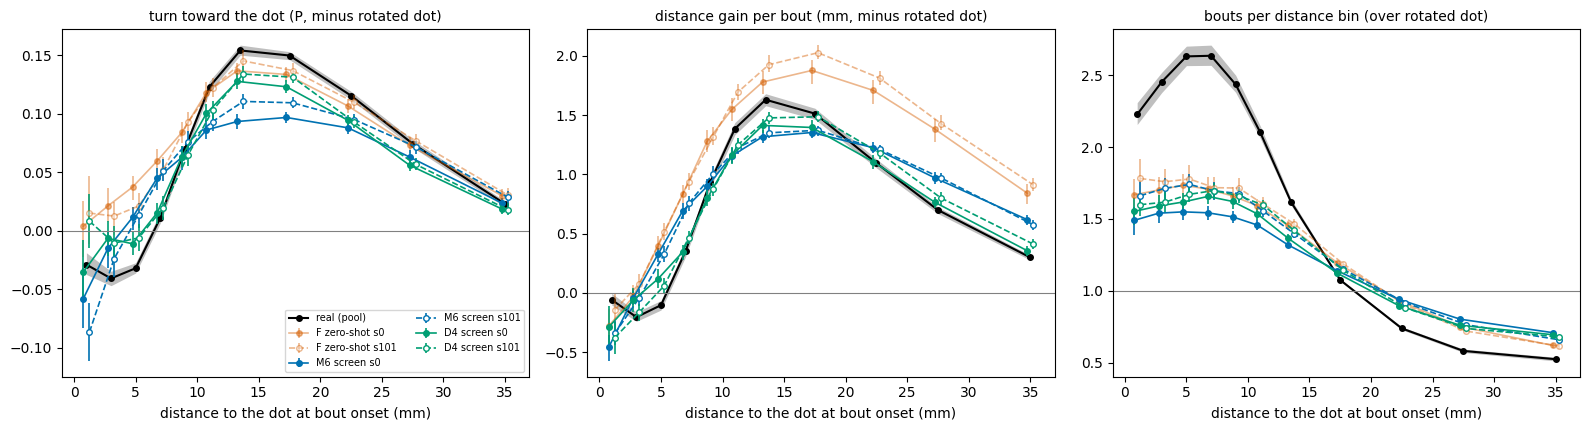

In [ ]:
if TR is not None:
    b = np.array(TR["dbins"]); xc = (b[:-1] + b[1:]) / 2; nb = 11
    titles = ["turn toward the dot (P, minus rotated dot)", "distance gain per bout (mm, minus rotated dot)",
              "bouts per distance bin (over rotated dot)"]
    col = {"M6 screen": "#0072B2", "D4 screen": "#009E73", "F zero-shot": "#D55E00"}
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
    for j, ax in enumerate(axs):
        r = TR["curves"]["real"]
        ax.fill_between(xc[:nb], np.array(r["lo"])[j, :nb], np.array(r["hi"])[j, :nb], color="0.75", lw=0)
        ax.plot(xc[:nb], np.array(r["est"])[j, :nb], "k-o", ms=4, label="real (pool)")
        for m in ("F zero-shot", "M6 screen", "D4 screen"):
            for s, ls, mf in ((0, "-", col[m]), (101, "--", "white")):
                c = TR["curves"][f"{m} s{s}"]
                y = np.array(c["est"])[j, :nb]
                err = np.vstack([y - np.array(c["lo"])[j, :nb], np.array(c["hi"])[j, :nb] - y])
                ax.errorbar(xc[:nb] + (0.25 if s else -0.25), y, yerr=err, fmt="o", ls=ls, color=col[m], mfc=mf, ms=4,
                            lw=1.2, capsize=0, alpha=0.45 if m == "F zero-shot" else 1.0, label=f"{m} s{s}")
        ax.axhline(1.0 if j == 2 else 0.0, color="0.5", lw=0.8)
        ax.set_xlabel("distance to the dot at bout onset (mm)"); ax.set_title(titles[j], fontsize=10)
    axs[0].legend(fontsize=7, ncol=2)
    plt.tight_layout()
    rows = {}
    for k in ["real"] + [f"{m} s{s}" for m in ("M6 zero-shot", "F zero-shot", "M6 screen", "D4 screen") for s in (0, 101)]:
        e = np.array(TR["curves"][k]["est"])
        rows[k] = {"turn toward 0-4 mm": e[0, :2].mean(), "turn toward 6-20 mm": e[0, 3:8].mean(),
                   "gain 0-4 mm": e[1, :2].mean(), "gain 6-20 mm": e[1, 3:8].mean(), "occupancy 4-10 mm": e[2, 2:5].mean()}
    print("minus chance (occupancy: over chance), mean over bins:")
    print(pd.DataFrame(rows).T.round(3).to_string())

closer than chance (mm): last 60 s of continuous motion -> 60-300 s of bout-like motion
  real                        2.87 ->  5.75  (change +2.88)
  M6 zero-shot s0 sighted     3.15 ->  3.37  (change +0.23)
  M6 zero-shot s101 sighted   3.15 ->  3.40  (change +0.25)
  F zero-shot s0 sighted      3.72 ->  3.54  (change -0.18)
  F zero-shot s101 sighted    3.54 ->  3.58  (change +0.04)
  M6 screen s0 sighted        2.91 ->  2.92  (change +0.01)
  M6 screen s0 decoupled      0.12 -> -0.04  (change -0.16)
  M6 screen s101 sighted      3.47 ->  3.58  (change +0.10)
  M6 screen s101 decoupled   -0.01 -> -0.04  (change -0.04)
  D4 screen s0 sighted        2.88 ->  2.94  (change +0.06)
  D4 screen s0 decoupled     -0.03 ->  0.09  (change +0.13)
  D4 screen s101 sighted      3.14 ->  3.34  (change +0.20)
  D4 screen s101 decoupled   -0.11 -> -0.07  (change +0.04)
  M6dm screen s0 sighted      4.19 ->  4.30  (change +0.11)
  M6dm screen s0 decoupled    0.04 ->  0.03  (change -0.01)
  M6dm scree

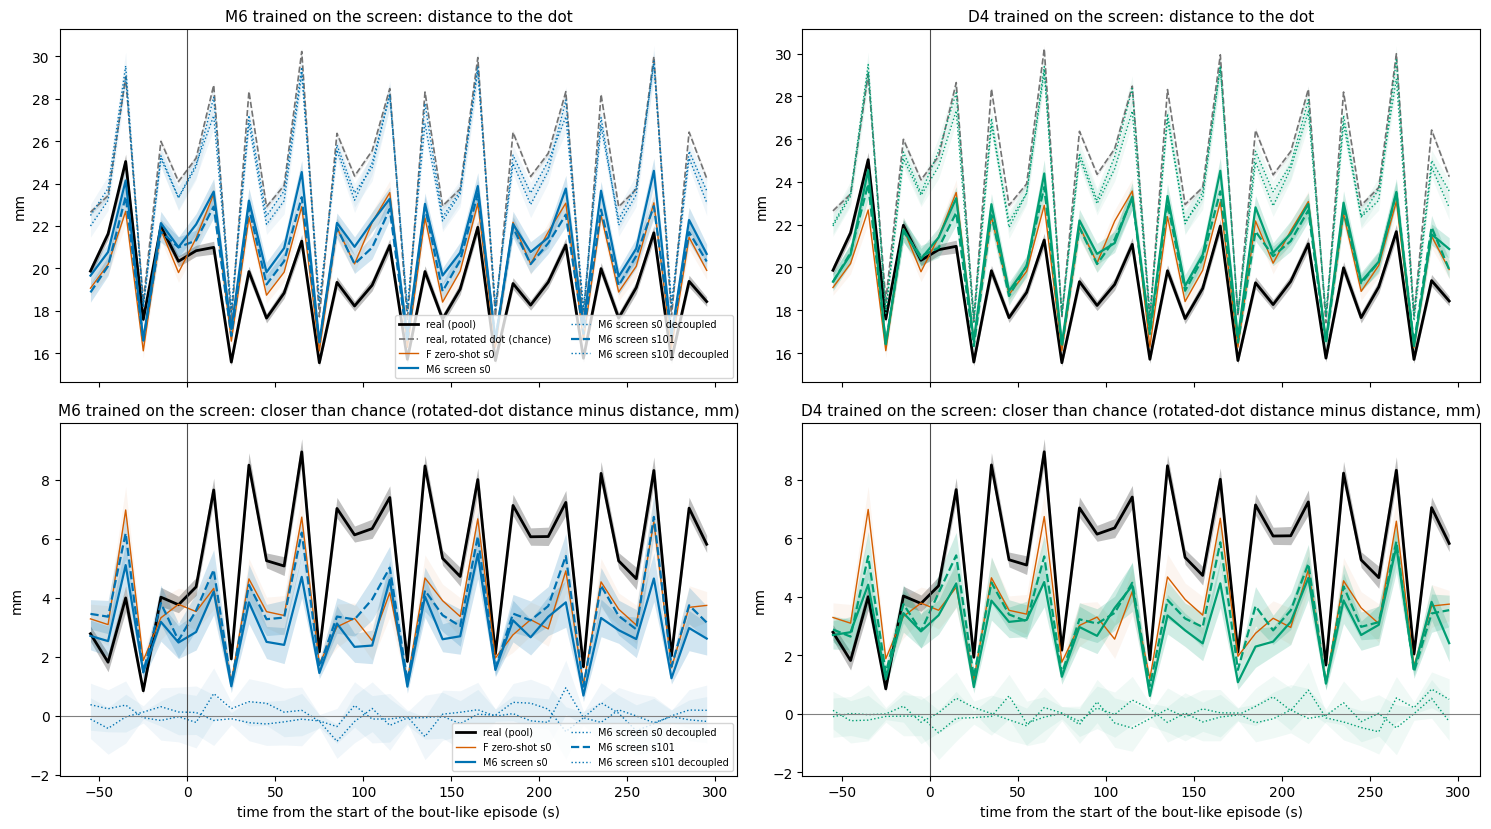

In [ ]:
if TR is not None:
    b = np.array(TR["pbins"]); xc = (b[:-1] + b[1:]) / 2
    col = {"M6": "#0072B2", "D4": "#009E73"}
    fig, axs = plt.subplots(2, 2, figsize=(15, 8.4), sharex=True)
    def band(ax, d, color, ls="-", lw=1.6, alpha=0.18, label=None):
        y = np.array(d["est"], float); lo = np.array(d["lo"], float); hi = np.array(d["hi"], float)
        ax.fill_between(xc, lo, hi, color=color, alpha=alpha, lw=0)
        ax.plot(xc, y, ls, color=color, lw=lw, label=label)
    for c, m in enumerate(("M6", "D4")):
        for row, key, ttl in ((0, "prof", "distance to the dot"),
                              (1, "attr", "closer than chance (rotated-dot distance minus distance, mm)")):
            ax = axs[row, c]
            band(ax, TR[key]["real"], "k", lw=2.0, alpha=0.25, label="real (pool)")
            if row == 0:
                band(ax, TR["prof"]["real, rotated dot"], "0.45", ls="--", lw=1.2, alpha=0.12, label="real, rotated dot (chance)")
            band(ax, TR[key]["F zero-shot s0 sighted"], "#D55E00", ls="-", lw=1.0, alpha=0.06, label="F zero-shot s0")
            for s, ls in ((0, "-"), (101, "--")):
                band(ax, TR[key][f"{m} screen s{s} sighted"], col[m], ls=ls, label=f"{m} screen s{s}")
                band(ax, TR[key][f"{m} screen s{s} decoupled"], col[m], ls=":", lw=1.0, alpha=0.06, label=f"{m} screen s{s} decoupled")
            if row == 1:
                ax.axhline(0, color="0.5", lw=0.8); ax.set_xlabel("time from the start of the bout-like episode (s)")
            ax.axvline(0, color="0.3", lw=0.8); ax.set_title(f"{m} trained on the screen: {ttl}", fontsize=11)
            ax.set_ylabel("mm")
    axs[0, 0].legend(fontsize=7, ncol=2, loc="lower right"); axs[1, 0].legend(fontsize=7, ncol=2, loc="lower right")
    plt.tight_layout()
    pre = (xc < 0); post = (xc > 60)
    print("closer than chance (mm): last 60 s of continuous motion -> 60-300 s of bout-like motion")
    for k in ["real"] + [u for u in TR["attr"] if u != "real"]:
        y = np.array(TR["attr"][k]["est"], float)
        print(f"  {k:26s} {np.nanmean(y[pre]):5.2f} -> {np.nanmean(y[post]):5.2f}  (change {np.nanmean(y[post]) - np.nanmean(y[pre]):+.2f})")

### 8b. What training on the screen changes

**Most of the zero-shot gap was the population.** Trained on 100 screen fish, the models are much harder to tell from
held-out screen fish: $\mathrm{AUC}$ 0.851 | 0.832 for M6 and 0.872 | 0.843 for D4 with all features, against
0.950–0.954 for the zero-shot M6 and F on the same real samples; on the 30 turn, step and interval features
0.75–0.82 against 0.92–0.93 (our own real fish score 0.870 there, section 2b). They swim like screen fish: median
|turn| 37.3–38.6° (real 38.1°), displacement 4.2–4.3 mm (4.25), interval 1.19–1.26 s (1.17), where the zero-shot models
carry our fish's 41.8–45.2°, 4.3–4.7 mm and 1.35–1.45 s. They remain distinguishable (floor 0.56–0.58; higher than
the 0.52 of section 2 because each half of the held-out pool has only about 49 clutches, so a 200-fish sample holds
about four siblings per clutch, which the classifier can learn).

**The dot response is worth more.** On the fish-to-dot features alone the screen-trained models score 0.647–0.672,
against 0.825–0.832 for the same models with the dot decoupled: seeing the dot is worth 0.15–0.19 of $\mathrm{AUC}$,
against 0.10 for the zero-shot models, and the sighted level is below the zero-shot 0.684–0.719.

**Learned from the screen: backing off and the strength of the approach.** Within 4 mm the screen-trained models turn
away from the dot as real fish do (turn toward minus chance −0.04 | −0.06 for M6, −0.02 | 0.00 for D4; real −0.035;
zero-shot M6 +0.08, F +0.01), and they no longer over-approach from afar: distance gained per bout at 6–20 mm
1.08 | 1.14 (M6) and 1.02 | 1.11 mm (D4) against 1.16 mm for real fish and 1.46–1.58 mm zero-shot. The turn toward the dot
at 6–20 mm is slightly short (0.077–0.090 against 0.102).

**Not learned: the preferred distance.** Bouts start 4–10 mm from the dot 1.54–1.70 times as often as by chance, as for
the zero-shot models (1.65–1.74), against 2.57 for real fish: the occupancy stays flat from 0 to 10 mm even though the
training data now contain the ring. Over the bout-like episode the models stay 2.9–3.6 mm closer than chance,
against 5.8 mm for real fish, no closer than the zero-shot models; when the dot travels away from the centre they
still fall behind it. This is the failure the bout decomposition traced to alignment (section on the close range):
real fish hold their distance by moving along the dot's direction of motion, an input the model does not have, and
more data cannot supply it. As expected, they do not respond to the switch to bout-like motion either (change
+0.01 to +0.20 mm against +2.88 mm for real fish): they never saw continuous motion, and motion is only a flag.

**Individuality.** The latent learns the screen's own spread of tempo: between-fish spread of the interval 0.99 | 1.02
of real for M6 (zero-shot 1.8–2.3). Turning spreads too little between fish (0.36 | 0.56) and radial position too
little, as before (0.35 | 0.44). D4 depends on its drift gains, which the per-fold search sets anywhere from 0.15 to 5
(the same calibration lottery as on our data): at seed 0 every spread overshoots (turning 1.81, displacement 1.77, tempo
1.81), at seed 101 they straddle 1 (0.78, 1.27, 0.69); within a fish D4 varies 1.4–1.7 times as much as real fish,
M6 0.7–1.1.

**Reading.** The model class can learn most of what the screen fish do, including the backing off that our fifteen
fish never showed often enough to learn; the zero-shot failures were mostly about the data. The one that survives
training on the screen is the preferred distance, which is a missing input (the dot's direction of motion), not
missing data.

<a id="dmove"></a>
## 9. Quick check: M6 and D4 trained on the screen with the dot's direction of motion

The screen-trained models learn to back off but not to move with the dot (section 8), and they see the dot's
position but never its motion. Here the screen-trained M6 and D4 get **one extra input** (Model 51, `stim_dmove`): the
direction in which the dot's centroid moved between the previous bout's onset and this one, as [sin, cos] relative to
the fish's reference heading. It is known at the bout's onset (no look-ahead), and it is 0 on the first bout of a run,
on bouts without moving dots and when the dot moved less than 0.5 mm. Everything else is as for M6 and D4 in section 8
(D4 with its own drift-gain search, as there):
same 100 fish, folds, seeds, training and evaluation, against the same real fish. A quick check, not a tuned model:
does this input alone bring the alignment, and with it the preferred distance?

In [ ]:
if TR is not None and "M6dm screen s0 sighted" in TR["auc"]["all"]:
    _ms = [m for m in ("M6", "M6dm", "D4", "D4dm") if f"{m} screen s0 sighted" in TR["auc"]["all"]]
    rows = ["real vs real"] + [f"{m} screen s{s} {v}" for m in _ms for s in (0, 101) for v in ("sighted", "decoupled")]
    def f(v): return f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}"
    print("window classifier, held-out clutches (M6, D4 = section 8; M6dm, D4dm = + dot motion direction; unmatched, see section 10):")
    print(pd.DataFrame({r: {k: f(TR["auc"][r][k]) for k in rows} for r in TR["auc"]}).to_string())
    print()
    ch = ["turn", "displacement", "interval", "radial"]
    print("individuality, simulated over real (between / within):")
    print(pd.DataFrame({k: {c: f"{TR['indiv'][k]['est']['between'][j]:.2f} / {TR['indiv'][k]['est']['within'][j]:.2f}"
                            for j, c in enumerate(ch)} for k in [f"{m} screen s{s}" for m in _ms for s in (0, 101)]}).T.to_string())
    print()
    ch = ["|turn| (deg)", "displacement (mm)", "interval (s)", "radial (r/R)"]
    print("kinematics:")
    print(pd.DataFrame({k: dict(zip(ch, [round(x, 3) for x in TR["kin"][k]])) for k in
                        ["real"] + [f"{m} screen s{s} sighted" for m in _ms for s in (0, 101)]}).T.to_string())
else:
    print("XX — screen_train.py run / sim / analyse for M6dm not done yet")

window classifier, held-out clutches (M6, D4 = section 8; M6dm, D4dm = + dot motion direction; unmatched, see section 10):
                                      all      no radial       dot only    30 features
real vs real                0.577 ± 0.023  0.569 ± 0.022  0.513 ± 0.010  0.564 ± 0.021
M6 screen s0 sighted        0.851 ± 0.007  0.822 ± 0.006  0.672 ± 0.019  0.773 ± 0.009
M6 screen s0 decoupled      0.915 ± 0.006  0.898 ± 0.006  0.825 ± 0.011  0.769 ± 0.011
M6 screen s101 sighted      0.832 ± 0.009  0.797 ± 0.011  0.647 ± 0.016  0.747 ± 0.013
M6 screen s101 decoupled    0.912 ± 0.007  0.893 ± 0.006  0.832 ± 0.009  0.749 ± 0.016
M6dm screen s0 sighted      0.812 ± 0.009  0.774 ± 0.010  0.601 ± 0.015  0.745 ± 0.013
M6dm screen s0 decoupled    0.918 ± 0.004  0.898 ± 0.004  0.837 ± 0.009  0.752 ± 0.012
M6dm screen s101 sighted    0.831 ± 0.008  0.795 ± 0.008  0.601 ± 0.016  0.769 ± 0.011
M6dm screen s101 decoupled  0.924 ± 0.004  0.908 ± 0.004  0.842 ± 0.011  0.767 ± 0.007
D4 scre

minus chance (occupancy: over chance):
                  turn toward 0-2 mm  turn toward 2-6 mm  turn toward 6-20 mm  gain 0-4 mm  gain 6-20 mm  occupancy 4-10 mm  occupancy 0-2 / 4-8
real                          -0.029              -0.036                0.102       -0.131         1.163              2.567                0.846
M6 screen s0                  -0.058              -0.002                0.077       -0.250         1.083              1.536                0.964
M6 screen s101                -0.087              -0.005                0.088       -0.189         1.142              1.704                0.967
M6dm screen s0                -0.084              -0.012                0.087       -0.209         1.015              1.948                1.019
M6dm screen s101              -0.109              -0.010                0.083       -0.098         1.144              2.001                0.949
D4 screen s0                  -0.035              -0.009                0.086       -0.175 

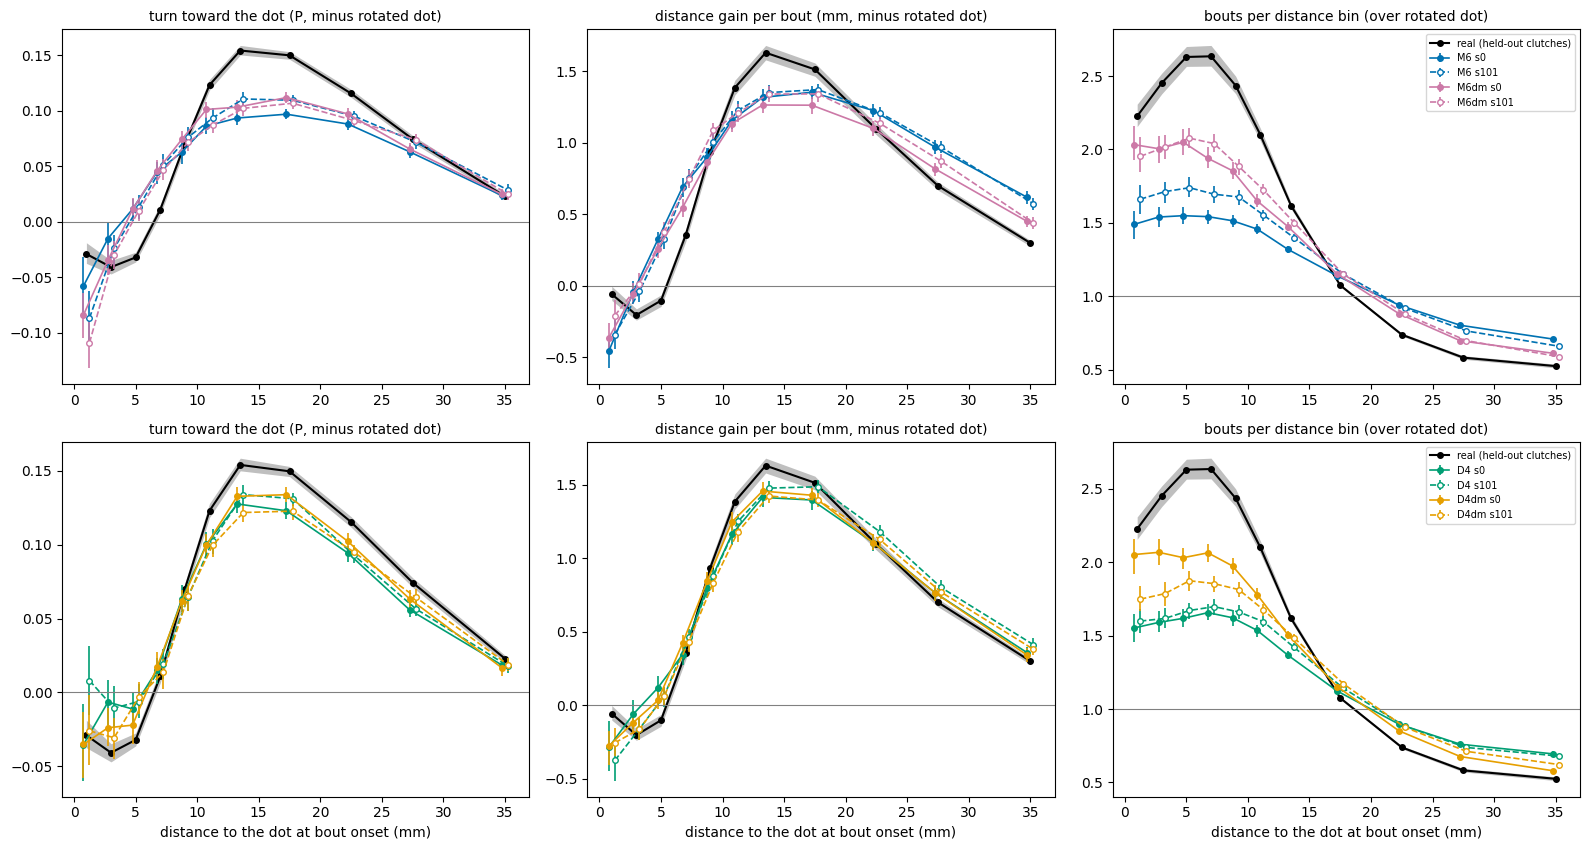

In [ ]:
PAIRS = [(a, b) for a, b in (("M6", "M6dm"), ("D4", "D4dm")) if TR is not None and f"{b} screen s0" in TR["curves"]]
DMCOL = {"M6": "#0072B2", "M6dm": "#CC79A7", "D4": "#009E73", "D4dm": "#E69F00"}
if PAIRS:
    b = np.array(TR["dbins"]); xc = (b[:-1] + b[1:]) / 2; nb = 11
    titles = ["turn toward the dot (P, minus rotated dot)", "distance gain per bout (mm, minus rotated dot)",
              "bouts per distance bin (over rotated dot)"]
    fig, axs = plt.subplots(len(PAIRS), 3, figsize=(16, 4.3 * len(PAIRS)), squeeze=False)
    for row, pair in enumerate(PAIRS):
        for j in range(3):
            ax = axs[row, j]
            r = TR["curves"]["real"]
            ax.fill_between(xc[:nb], np.array(r["lo"])[j, :nb], np.array(r["hi"])[j, :nb], color="0.75", lw=0)
            ax.plot(xc[:nb], np.array(r["est"])[j, :nb], "k-o", ms=4, label="real (held-out clutches)")
            for m in pair:
                for s, ls, mf in ((0, "-", DMCOL[m]), (101, "--", "white")):
                    c = TR["curves"][f"{m} screen s{s}"]; y = np.array(c["est"])[j, :nb]
                    err = np.vstack([y - np.array(c["lo"])[j, :nb], np.array(c["hi"])[j, :nb] - y])
                    ax.errorbar(xc[:nb] + (0.25 if s else -0.25), y, yerr=err, fmt="o", ls=ls, color=DMCOL[m], mfc=mf,
                                ms=4, lw=1.2, capsize=0, label=f"{m} s{s}")
            ax.axhline(1.0 if j == 2 else 0.0, color="0.5", lw=0.8)
            ax.set_title(titles[j], fontsize=10)
            if row == len(PAIRS) - 1:
                ax.set_xlabel("distance to the dot at bout onset (mm)")
        axs[row, 2].legend(fontsize=7, ncol=1)
    plt.tight_layout()
    rows = {}
    for k in ["real"] + [f"{m} screen s{s}" for p_ in PAIRS for m in p_ for s in (0, 101)]:
        e = np.array(TR["curves"][k]["est"])
        rows[k] = {"turn toward 0-2 mm": e[0, 0], "turn toward 2-6 mm": e[0, 1:3].mean(), "turn toward 6-20 mm": e[0, 3:8].mean(),
                   "gain 0-4 mm": e[1, :2].mean(), "gain 6-20 mm": e[1, 3:8].mean(), "occupancy 4-10 mm": e[2, 2:5].mean(),
                   "occupancy 0-2 / 4-8": e[2, 0] / e[2, 2:4].mean()}
    print("minus chance (occupancy: over chance):")
    print(pd.DataFrame(rows).T.round(3).to_string())

bout decomposition (minus chance) and time-weighted shape:
                  along 2-10 mm  toward 2-6 mm  align cos 0-10 mm  time 0-2 / 4-8 mm
real (pool)               0.561         -0.227              0.369              0.696
M6 screen s0              0.211         -0.008              0.118              0.950
M6 screen s101            0.214         -0.035              0.141              0.926
M6dm screen s0            0.412         -0.095              0.247              0.976
M6dm screen s101          0.377         -0.062              0.256              0.937
D4 screen s0              0.224         -0.048              0.112              0.894
D4 screen s101            0.224         -0.055              0.127              0.886
D4dm screen s0            0.485         -0.111              0.261              0.904
D4dm screen s101          0.385         -0.173              0.222              0.886


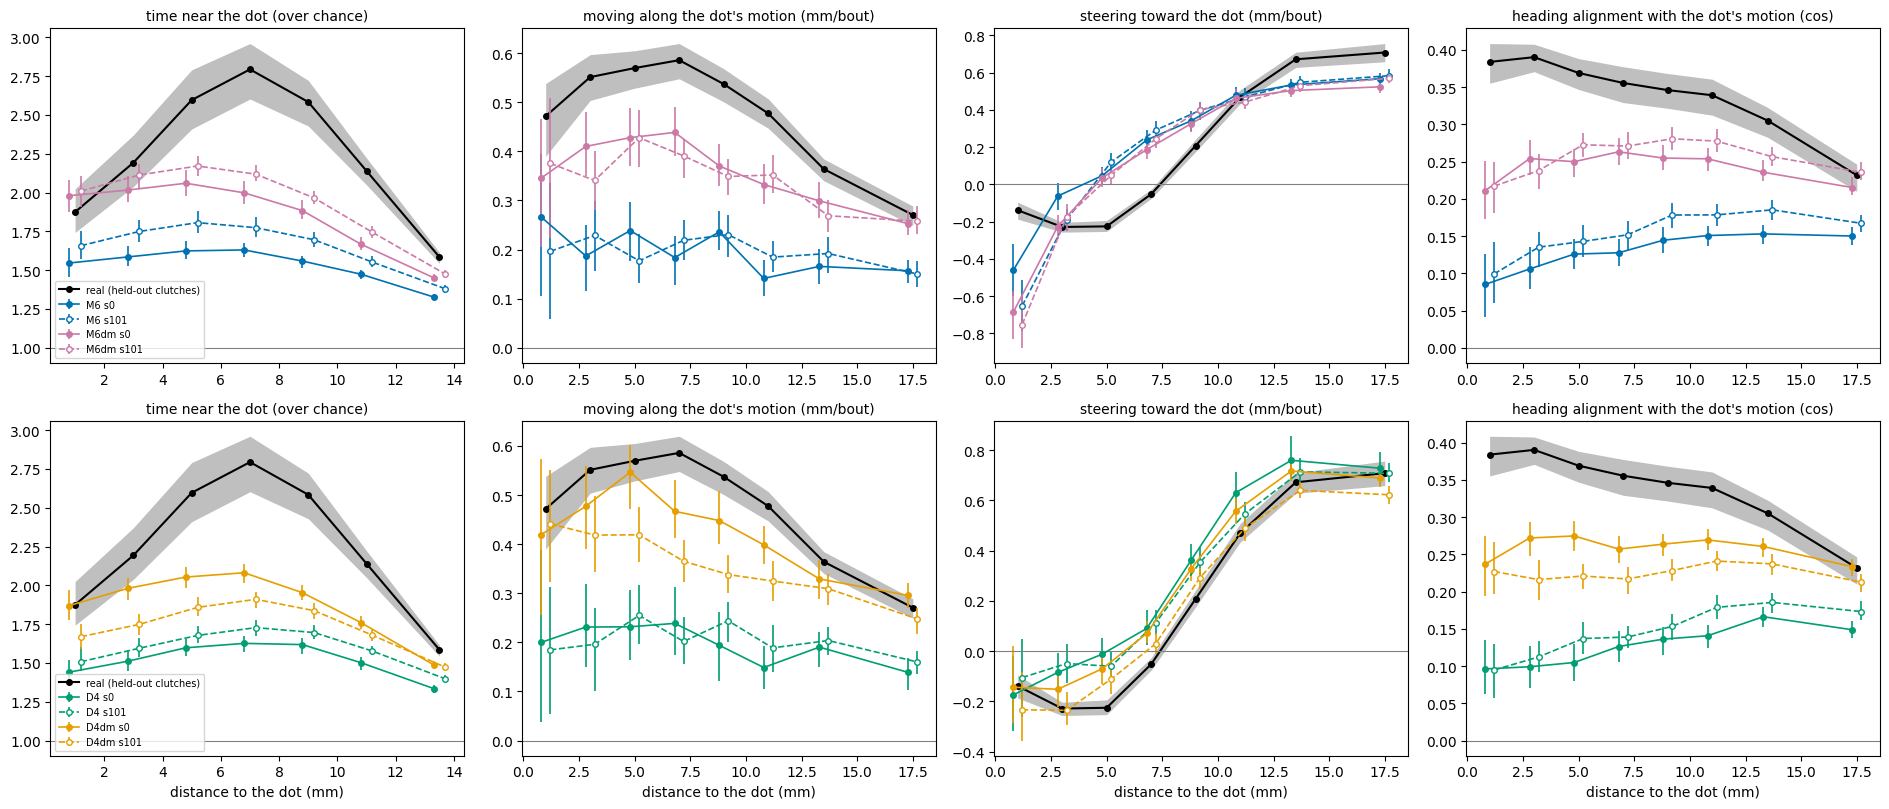

In [ ]:
CRp = "twin_test/screen_closerange.json"
if PAIRS and os.path.exists(CRp):
    CR = json.load(open(CRp)); S = CR["sides"]; b = np.array(CR["bins"]); xc = (b[:-1] + b[1:]) / 2
    PC = [p_ for p_ in PAIRS if f"{p_[1]} screen s0" in S]
    qs = (("tocc", "time near the dot (over chance)", 7), ("along_x", "moving along the dot's motion (mm/bout)", 8),
          ("toward_x", "steering toward the dot (mm/bout)", 8), ("align_x", "heading alignment with the dot's motion (cos)", 8))
    fig, axs = plt.subplots(len(PC), 4, figsize=(19, 4.1 * len(PC)), squeeze=False)
    for row, pair in enumerate(PC):
        for ax, (q, t, n) in zip(axs[row], qs):
            d = S["real (pool)"][q]
            ax.fill_between(xc[:n], np.array(d["lo"])[:n], np.array(d["hi"])[:n], color="0.75", lw=0)
            ax.plot(xc[:n], np.array(d["est"])[:n], "k-o", ms=4, label="real (held-out clutches)")
            for m in pair:
                for s, ls, mf in ((0, "-", DMCOL[m]), (101, "--", "white")):
                    d = S[f"{m} screen s{s}"][q]; y = np.array(d["est"])[:n]
                    err = np.vstack([y - np.array(d["lo"])[:n], np.array(d["hi"])[:n] - y])
                    ax.errorbar(xc[:n] + (0.2 if s else -0.2), y, yerr=err, fmt="o", ls=ls, color=DMCOL[m], mfc=mf, ms=4,
                                lw=1.2, capsize=0, label=f"{m} s{s}")
            ax.axhline(1.0 if q == "tocc" else 0.0, color="0.5", lw=0.8); ax.set_title(t, fontsize=10)
            if row == len(PC) - 1:
                ax.set_xlabel("distance to the dot (mm)")
        axs[row, 0].legend(fontsize=7)
    plt.tight_layout()
    rows = {}
    for k in ["real (pool)"] + [f"{m} screen s{s}" for p_ in PC for m in p_ for s in (0, 101)]:
        e = {q: np.array(S[k][q]["est"]) for q in ("tocc", "along_x", "toward_x", "align_x")}
        rows[k] = {"along 2-10 mm": e["along_x"][1:5].mean(), "toward 2-6 mm": e["toward_x"][1:3].mean(),
                   "align cos 0-10 mm": e["align_x"][:5].mean(), "time 0-2 / 4-8 mm": e["tocc"][0] / e["tocc"][2:4].mean()}
    print("bout decomposition (minus chance) and time-weighted shape:")
    print(pd.DataFrame(rows).T.round(3).to_string())
else:
    print("XX — screen_report_extras.py closerange not run for the direction models yet")

closer than chance (mm), bout-like motion: dot near the centre | dot travelling out
  real                        3.37 |  7.98
  M6 screen s0 sighted        1.74 |  5.11
  M6 screen s101 sighted      2.10 |  5.86
  M6dm screen s0 sighted      2.46 |  6.45
  M6dm screen s101 sighted    2.56 |  6.90
  D4 screen s0 sighted        2.11 |  5.41
  D4 screen s101 sighted      2.29 |  5.76
  D4dm screen s0 sighted      2.76 |  7.07
  D4dm screen s101 sighted    2.27 |  6.32


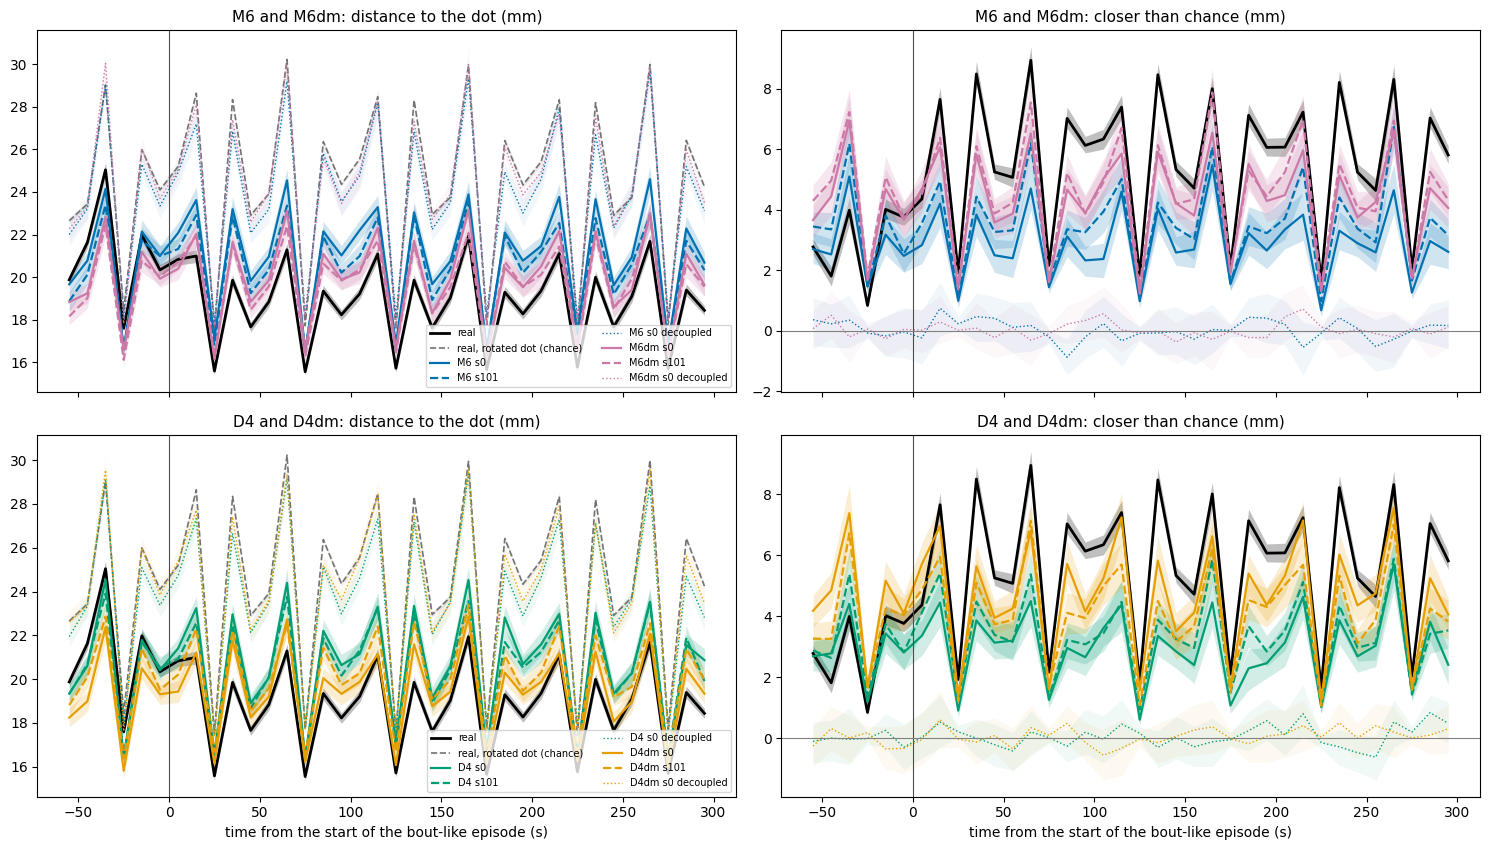

In [ ]:
if PAIRS and all(f"{p_[1]} screen s0 sighted" in TR["prof"] for p_ in PAIRS):
    b = np.array(TR["pbins"]); xc = (b[:-1] + b[1:]) / 2
    fig, axs = plt.subplots(len(PAIRS), 2, figsize=(15, 4.3 * len(PAIRS)), sharex=True, squeeze=False)
    def band(ax, d, color, ls="-", lw=1.6, alpha=0.18, label=None):
        y = np.array(d["est"], float); lo = np.array(d["lo"], float); hi = np.array(d["hi"], float)
        ax.fill_between(xc, lo, hi, color=color, alpha=alpha, lw=0); ax.plot(xc, y, ls, color=color, lw=lw, label=label)
    for row, pair in enumerate(PAIRS):
        for ax, key, ttl in ((axs[row, 0], "prof", "distance to the dot (mm)"),
                             (axs[row, 1], "attr", "closer than chance (mm)")):
            band(ax, TR[key]["real"], "k", lw=2.0, alpha=0.25, label="real")
            if key == "prof":
                band(ax, TR["prof"]["real, rotated dot"], "0.45", ls="--", lw=1.2, alpha=0.12, label="real, rotated dot (chance)")
            for m in pair:
                for s, ls in ((0, "-"), (101, "--")):
                    band(ax, TR[key][f"{m} screen s{s} sighted"], DMCOL[m], ls=ls, label=f"{m} s{s}")
                band(ax, TR[key][f"{m} screen s0 decoupled"], DMCOL[m], ls=":", lw=1.0, alpha=0.06, label=f"{m} s0 decoupled")
            ax.axvline(0, color="0.3", lw=0.8); ax.set_title(f"{pair[0]} and {pair[1]}: {ttl}", fontsize=11)
            if row == len(PAIRS) - 1:
                ax.set_xlabel("time from the start of the bout-like episode (s)")
        axs[row, 1].axhline(0, color="0.5", lw=0.8); axs[row, 0].legend(fontsize=7, ncol=2, loc="lower right")
    plt.tight_layout()
    DR = json.load(open("twin_test/screen_pbins_dotr.json"))          # the dot's r/R per 10 s bin (fixed path)
    rb = np.array(DR["dot_r_over_R"]); P = np.array(DR["pbins"]); post = P[:-1] >= 0
    lo = post & (rb < np.percentile(rb[post], 33)); hi = post & (rb > np.percentile(rb[post], 67))
    ch_ = np.array(TR["prof"]["real, rotated dot"]["est"])
    print("closer than chance (mm), bout-like motion: dot near the centre | dot travelling out")
    for k in ["real"] + [f"{m} screen s{s} sighted" for p_ in PAIRS for m in p_ for s in (0, 101)]:
        y = np.array(TR["prof"][k]["est"]); print(f"  {k:26s} {np.nanmean((ch_ - y)[lo]):5.2f} | {np.nanmean((ch_ - y)[hi]):5.2f}")

### 9b. Does the direction of motion bring alignment?

**Partly, in both models and at both seeds: about half of the missing alignment.** With the dot's direction of motion
as an input, the bouts move along the dot's motion by +0.41 | +0.38 mm (M6) and +0.49 | +0.39 mm (D4) at 2–10 mm,
against +0.21–0.22 without it and +0.56 for real fish; the heading lines up with that motion at a cosine of
0.25 | 0.26 (M6) and 0.26 | 0.22 (D4) above chance within 10 mm, against 0.11–0.14 without it and 0.37 for real fish.
Close to the dot the models also steer toward its position less (2–6 mm: −0.10 | −0.06 for M6, −0.11 | −0.17 for D4,
against −0.01 to −0.06 without the input, real −0.23); D4 comes closest.

**With it comes part of the preferred distance and of the following.** Bouts start 4–10 mm from the dot 1.95 | 2.00
(M6) and 2.02 | 1.85 (D4) times as often as by chance, against 1.54–1.70 without the input and 2.57 for real fish.
When the dot travels away from the dish centre, the models stay 6.5 | 6.9 (M6) and 7.1 | 6.3 mm (D4) closer than
chance, against 5.1–5.9 without the input and 8.0 for real fish. On the fish-to-dot features alone the matched
classifier falls from 0.680 | 0.651 to 0.617 | 0.605 (M6) and from 0.704 | 0.667 to 0.631 | 0.639 (D4); with all
features it improves at seed 0 (M6 0.851 → 0.816, D4 0.873 → 0.826) and stays at seed 101 (0.824 → 0.833, 0.844 →
0.842; section 10). Kinematics are unchanged. D4's between-fish spreads now sit near the real ones at seed 0 (turning
1.01, displacement 1.27, tempo 0.88), but its drift gains were again drawn from 0.15 to 5 across folds, so this is the
drift lottery more than the input.

**Not fixed: the gap at contact.** Relative to 4–8 mm, the time spent within 2 mm of the dot stays flat in every model
(0.89–0.98 time-weighted, real 0.70; 0.94–1.02 in bouts, real 0.85). The turn away within 2 mm is at or beyond the
real one, but nothing turns away at 2–6 mm.

**Reading.** The dot's direction of motion is a real missing ingredient, and the result replicates across two models
and two seeds: one input, nothing else changed, brings the model about halfway to the real alignment and about 40 %
of the way to the real preferred distance. It is not the whole story. Real fish align more strongly, and they keep a
gap at contact that no variant reproduces. The direction over one inter-bout interval is a crude description of the
dot's motion; its speed, its bout timing and a longer history are the obvious next candidates.

<a id="matched"></a>
## 10. Matched window classifier

The classifier of sections 2 and 8 compares real and simulated windows drawn independently. Real fish rest and lose
tracking, so their windows are missing at some moments of the session, whereas simulated fish never pause and cover
it evenly. The **matched** classifier removes this, as the thesis's matched $\mathrm{AUC}$ does on our own data: every
simulated fish is paired with real fish (real fish of rank *j* with simulated fish *j* mod 200), and every window of a
real fish (60 bouts inside one run of a bout-like episode) is set against the window of its paired simulated fish that
starts at the **same frame of the session**: the first kept bout at or after it, moved back if the run ends within
60 bouts. Both sides then see the same moments of the dot's fixed path, one to one. Readings, replicates, real
samples, folds and forests are unchanged, the 15-fish column uses 20 replicates and folds stratified by class, and the
real-against-real floors are unmatched by nature (both sides real). Permutation importances are on replicate 0
(`scripts/screen_matched.py`). Each value is mean ± SD over replicates; seed 0 and seed 101 are separate rows.

In [ ]:
MP = "twin_test/screen_matched.json"
if os.path.exists(MP):
    MA = json.load(open(MP))
    def f(v): return f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}"
    for blk, ttl in (("zero-shot", "Zero-shot models against all screen fish"),
                     ("screen-trained", "Held-out clutches: zero-shot re-read, screen-trained, + dot direction")):
        if blk not in MA:
            continue
        B_ = MA[blk]
        units = list(B_["auc"]["all"])
        tab = pd.DataFrame({r: {u: f(B_["auc"][r][u]) for u in units} for r in B_["auc"]})
        tab["all, 15 fish"] = pd.Series({u: f(B_["auc15"][u]) for u in units if u in B_["auc15"]})
        print(f"{ttl} (matched AUC; {B_['n_real']} real fish):")
        print(tab[["all", "all, 15 fish", "no radial", "dot only", "30 features"]].to_string())
        print()
    if "screen-trained" in MA and MA["screen-trained"]["imp"]:
        I_ = MA["screen-trained"]["imp"]
        print("share of the positive permutation importance (matched, replicate 0):")
        print(pd.DataFrame({u: {g: f"{100 * v:.0f} %" for g, v in d["share"].items()} for u, d in I_.items()}).T.to_string())
        print()
        print("three leading features:")
        for u, d in I_.items():
            top = sorted(zip(d["imp"], d["names"]), reverse=True)[:3]
            print(f"  {u:30s} " + ", ".join(f"{n} {v * 1e3:.1f}" for v, n in top))
    print()
    print("matched minus unmatched (all features), where both exist:")
    for u in MA.get("screen-trained", {}).get("auc", {}).get("all", {}):
        if TR is not None and u in TR["auc"]["all"] and u != "real vs real":
            print(f"  {u:30s} {np.mean(MA['screen-trained']['auc']['all'][u]) - np.mean(TR['auc']['all'][u]):+.3f}")
else:
    print("XX — scripts/screen_matched.py not run yet")

Zero-shot models against all screen fish (matched AUC; 2809 real fish):
                           all   all, 15 fish      no radial       dot only    30 features
real vs real     0.516 ± 0.023  0.510 ± 0.121  0.515 ± 0.022  0.500 ± 0.003  0.510 ± 0.026
M6 s0 sighted    0.950 ± 0.004  0.892 ± 0.056  0.936 ± 0.006  0.737 ± 0.015  0.927 ± 0.007
M6 s0 blind      0.967 ± 0.003  0.928 ± 0.039  0.951 ± 0.004  0.822 ± 0.010  0.924 ± 0.009
M6 s101 sighted  0.956 ± 0.003  0.887 ± 0.048  0.940 ± 0.004  0.762 ± 0.009  0.929 ± 0.004
M6 s101 blind    0.968 ± 0.002  0.926 ± 0.033  0.953 ± 0.004  0.837 ± 0.009  0.925 ± 0.004
F s0 sighted     0.948 ± 0.004  0.877 ± 0.046  0.936 ± 0.006  0.750 ± 0.010  0.924 ± 0.006
F s0 blind       0.963 ± 0.004  0.910 ± 0.039  0.949 ± 0.007  0.827 ± 0.012  0.918 ± 0.009
F s101 sighted   0.953 ± 0.003  0.914 ± 0.035  0.942 ± 0.003  0.776 ± 0.013  0.934 ± 0.004
F s101 blind     0.961 ± 0.003  0.928 ± 0.029  0.948 ± 0.003  0.842 ± 0.008  0.915 ± 0.006

Held-out clutches

### 10b. What matching changes

**Almost nothing with all features.** Matching moves every model's $\mathrm{AUC}$ by −0.008 to +0.008, within the
replicate noise (section 10 table, last block). The real fish's missing moments of the session, where they rest or
lose tracking, did not help the classifier.

**More on the fish-to-dot features, for the zero-shot models.** There the matched values are 0.02–0.04 higher for
the sighted zero-shot models (M6 0.737 | 0.762, F 0.750 | 0.776, against 0.698–0.732 unmatched) and only about 0.01
higher blind (0.822–0.842). Seeing the dot is therefore worth 0.07–0.09 of $\mathrm{AUC}$ in the zero-shot models
rather than 0.10, and 0.13–0.17 in the screen-trained ones. The 15-fish values rise slightly as well (zero-shot
0.88–0.91 against 0.86–0.88).

**The tells are the same.** Zero-shot, the matched classifier tells the models from the screen fish by tempo (35–48 %
of the positive importance, led by the within-window interval SD), step variability (16–26 %) and radial position
(12–23 %), hardly by the dot (4–8 %). Trained on the screen, the distance to the dot becomes a main tell (21–34 %,
led by its median), next to tempo (18–39 %) and radial position (19–27 %). With the direction input the dot-distance
share falls to 12–17 %, and the radial position and tempo are left as the main tells.

**Reading.** The headline numbers stand; only the fish-to-dot reading of the zero-shot models and the 15-fish column
shift, and the ranking of every model is unchanged.